# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB   (W x H x C x B, 1 MB = 1024^2 bytes)
frame_bytes = 1920 * 1080 * 3 * 1
frame_mb = frame_bytes / 1024**2

# TODO 2: frames per camera per day at 30 fps   (N = f x T)
frames_per_day = 30 * 24 * 3600

# TODO 3: 400 cameras x 24 h, uncompressed, in TB   (1 TB = 1024^4 bytes)
fleet_bytes = 400 * frames_per_day * frame_bytes
fleet_tb = fleet_bytes / 1024**4

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
small_frame_bytes = 640 * 360 * 3 * 1
fleet_tb_small = 400 * (10 * 24 * 3600) * small_frame_bytes / 1024**4
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

# what the two cuts contribute separately -- spatial and temporal are independent levers
print(f"\nSpatial cut alone : x{(1920*1080)/(640*360):.0f} fewer pixels per frame")
print(f"Temporal cut alone: x{30/10:.0f} fewer frames per second")
print(f"Combined          : x{fleet_tb/fleet_tb_small:.0f} less storage "
      f"({fleet_tb - fleet_tb_small:,.1f} TB/day saved, {fleet_tb_small/fleet_tb:.2%} of the original kept)")
print(f"Per camera per day: {fleet_tb*1024/400:,.1f} GB (1080p30) vs {fleet_tb_small*1024/400:,.1f} GB (360p10)")


One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%

Spatial cut alone : x9 fewer pixels per frame
Temporal cut alone: x3 fewer frames per second
Combined          : x27 less storage (5,648.7 TB/day saved, 3.70% of the original kept)
Per camera per day: 15,016.9 GB (1080p30) vs 556.2 GB (360p10)


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_

**Spatial evidence lost: identifying detail on faces and number plates.** 360p keeps only **11.11%** of the pixels of
1080p (9x fewer), so a plate that is 60 px wide at 1080p becomes 20 px wide — a few pixels per character, below the point
where it can be read. That loss is permanent: enlarging the stored 360p frame later is **raster interpolation**
(Slide 13), which *invents* in-between pixels from their neighbours; it can make the image smoother but can never put back
the strokes of a character that were averaged away.

**Temporal evidence lost: anything brief or fast between frames.** Going from 30 fps to 10 fps stretches the gap between
frames from **33.3 ms to 100 ms**. A short action — the hand swing that breaks a window, the moment a door is forced —
can fall entirely *between* two stored frames. Fast motion also jumps 3x further per frame, which is the
**correspondence problem** (Slides 36–37): with large jumps the analyst (or a tracker) can no longer tell which blob in
frame *n+1* is the person from frame *n*, so a trajectory — e.g. *which direction the runner went* — becomes ambiguous.
The 27x storage saving (5,866 → 217 TB/day) is real, but it is paid for exactly in the evidence an incident review needs.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

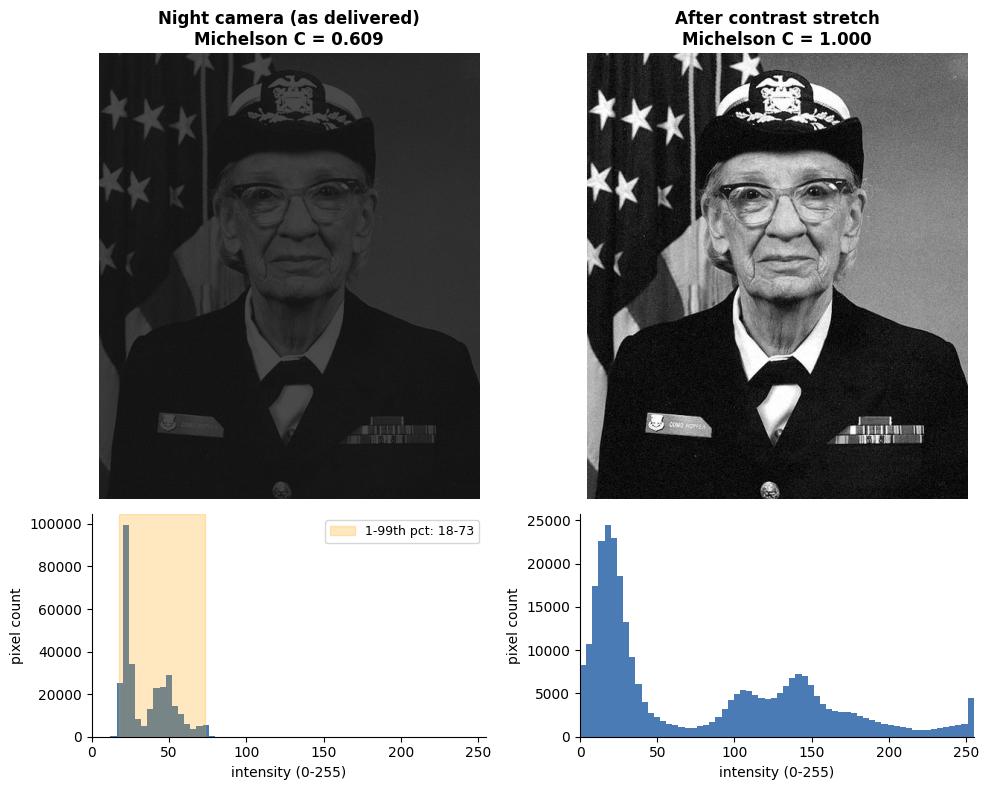

Contrast before: 0.609  ->  after: 1.000

Occupied range before: 17.8 to 73.4  = 55.6 of 255 levels (22% of the scale)
Mean intensity before: 34.9   after: 78.5
Distinct 8-bit levels in the delivered image: 67  -> after stretching that 8-bit image: 58
  -> never more: the stretch only spaces existing levels further apart, and clipping merges the darkest/brightest 1% into 0 and 255


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still (1st / 99th percentile as L_min / L_max)
p1, p99 = np.percentile(night_still, [1, 99])
c_before = michelson(p99, p1)

# TODO 3: contrast-stretched version of night_still  (p1 -> 0, p99 -> 255, clipped)
stretched = np.clip((night_still - p1) / (p99 - p1) * 255, 0, 255)

s1, s99 = np.percentile(stretched, [1, 99])
c_after = michelson(s99, s1)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
# vmin/vmax fixed to 0-255 on BOTH images: otherwise imshow auto-stretches the murky one
# and hides exactly the problem we are trying to show.
for col, (im, title, c) in enumerate([(night_still, "Night camera (as delivered)", c_before),
                                      (stretched, "After contrast stretch", c_after)]):
    axes[0, col].imshow(im, cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(f"{title}\nMichelson C = {c:.3f}", fontweight="bold")
    axes[0, col].axis("off")
    axes[1, col].hist(im.ravel(), bins=64, range=(0, 255), color="#4b7bb5")
    axes[1, col].set_xlim(0, 255)
    axes[1, col].set_xlabel("intensity (0-255)")
    axes[1, col].set_ylabel("pixel count")
axes[1, 0].axvspan(p1, p99, color="orange", alpha=0.25, label=f"1-99th pct: {p1:.0f}-{p99:.0f}")
axes[1, 0].legend(fontsize=9)

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

used = p99 - p1
print(f"\nOccupied range before: {p1:.1f} to {p99:.1f}  = {used:.1f} of 255 levels ({used/255:.0%} of the scale)")
print(f"Mean intensity before: {night_still.mean():.1f}   after: {stretched.mean():.1f}")
q8 = np.round(night_still).clip(0, 255)                                   # what an 8-bit camera stores
q8_stretched = np.round(np.clip((q8 - p1) / (p99 - p1) * 255, 0, 255))
print(f"Distinct 8-bit levels in the delivered image: {len(np.unique(q8))}  "
      f"-> after stretching that 8-bit image: {len(np.unique(q8_stretched))}\n"
      f"  -> never more: the stretch only spaces existing levels further apart, and clipping merges the "
      f"darkest/brightest 1% into 0 and 255")


**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_

**Shape:** a **narrow histogram bunched at the dark end** — the lecture's signature of a **dark, low-contrast** image.
Its 1st–99th percentile range is only **17.8 to 73.4**, i.e. **22%** of the 0–255 scale, with a mean of 34.9; the bright
70% of the scale is empty. Robust Michelson contrast is **0.609**.

**Why stretching helps without adding information.** The stretch is a monotonic remap: the darkest 1% go to 0, the
brightest 1% to 255, and everything in between is spread linearly (contrast → **1.000**). Neighbouring grey levels that
differed by 1 now differ by ~4.6, which pushes edges above what the eye can discriminate — so the face *becomes
visible*, but nothing was *added*. The proof is in the output: the 8-bit image had **67** distinct levels before and has
**58** after (clipping the 1% tails merged a few). Stretching relabels levels; it cannot create detail the sensor never
recorded, and it amplifies the sensor noise by the same factor.

**Why the histogram could never tell us what is in the picture** ("Same Histogram ≠ Same Image", Slide 18). A histogram
counts *how many* pixels have each value and throws away *where* they are. Shuffle every pixel of this photo randomly and
the histogram is identical, yet the image becomes noise. So the histogram is the right tool for the *diagnosis*
(exposure/contrast problem) and the wrong tool for *content* (who is in the frame).

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

STANDING (< 3 px/s):  68.70 s ->  78.10 s  (9.4 s, 91% of frames in that span meet the threshold)
RUNNING  (> 25 px/s):  78.60 s ->  86.00 s  (7.4 s, 100% of frames in that span meet the threshold)
Car visible   : 20.0 -> 32.0 s
Person visible: 40.0 -> 86.0 s
Peak person speed: 45.5 px/s at 79.3 s

Audio event   : frame 2250 = 75.00 s (-4.6 dB; background median -50.6 dB)
Lighting event: frame 3000 = 100.00 s (brightness 62 -> 148)


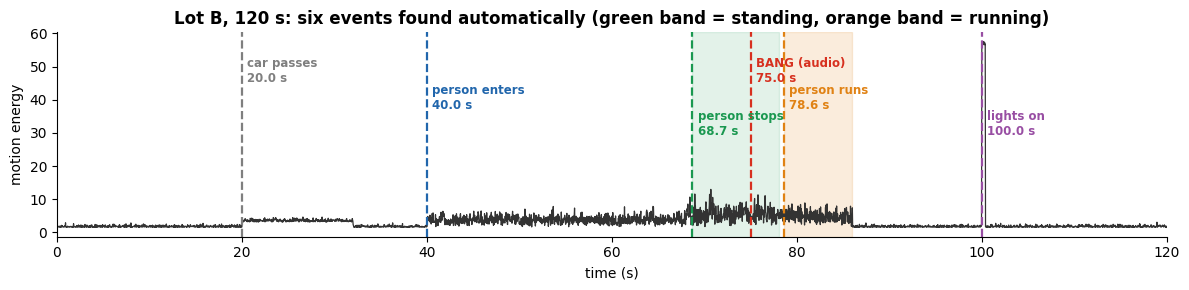

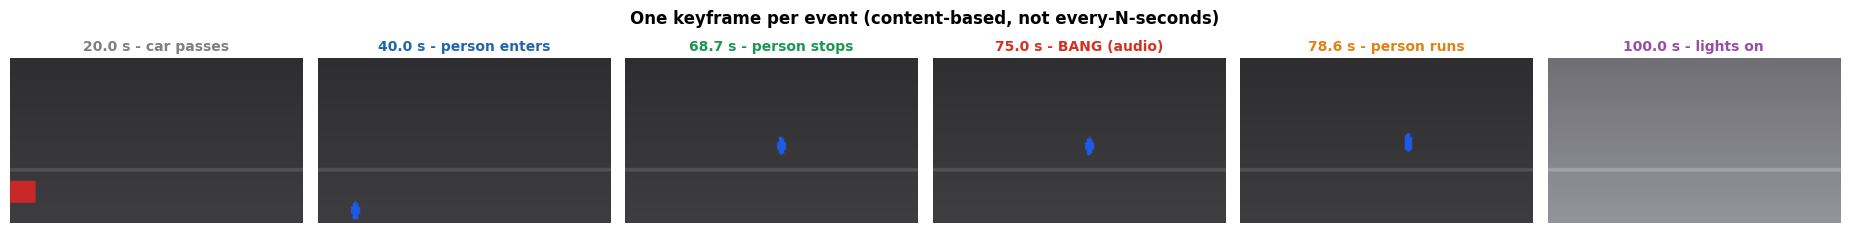

Uniform keyframes every 20 s would land at: [0.0, 20.0, 40.0, 60.0, 80.0, 100.0]
  car passes     at  20.00 s -> nearest uniform keyframe  0.0 s away
  person enters  at  40.00 s -> nearest uniform keyframe  0.0 s away
  person stops   at  68.70 s -> nearest uniform keyframe  8.7 s away
  BANG (audio)   at  75.00 s -> nearest uniform keyframe  5.0 s away
  person runs    at  78.60 s -> nearest uniform keyframe  1.4 s away
  lights on      at 100.00 s -> nearest uniform keyframe  0.0 s away


In [4]:
t = cctv.time_s

# TODO 1: person speed (px/s) -- motion-vector magnitude over a 1-second window (FPS frames)
speed = np.hypot(cctv.person_x.diff(FPS), cctv.person_y.diff(FPS))

# TODO 2: standing / running time ranges (print the first and last time of each)
is_standing = speed < 3
is_running = speed > 25
spans = {}
for name, m in [("STANDING (< 3 px/s)", is_standing), ("RUNNING  (> 25 px/s)", is_running)]:
    a, b = int(m.idxmax()), int(m[::-1].idxmax())          # first and last frame meeting the condition
    inside = m.iloc[a:b + 1].mean()
    spans[name] = (a, b)
    print(f"{name}: {t[a]:6.2f} s -> {t[b]:6.2f} s  ({t[b]-t[a]:.1f} s, "
          f"{inside:.0%} of frames in that span meet the threshold)")
standing = [spans["STANDING (< 3 px/s)"]]
running = [spans["RUNNING  (> 25 px/s)"]]
# the standing span is not 100%: tracking jitter pushes the 1-s speed just over 3 px/s now and then,
# which is exactly why the TODO uses a 1-second window instead of single-frame differences.

car_seen = cctv.car_x.notna(); person_seen = cctv.person_x.notna()
print(f"Car visible   : {t[car_seen].min():.1f} -> {t[car_seen].max():.1f} s")
print(f"Person visible: {t[person_seen].min():.1f} -> {t[person_seen].max():.1f} s")
print(f"Peak person speed: {speed.max():.1f} px/s at {t[speed.idxmax()]:.1f} s")

# TODO 3: event frame indices
audio_event_idx = int((cctv.audio_level_db > -20).idxmax())            # first frame above -20 dB
lighting_event_idx = int((cctv.mean_brightness.diff() > 40).idxmax())   # first one-frame jump > 40
print(f"\nAudio event   : frame {audio_event_idx} = {t[audio_event_idx]:.2f} s "
      f"({cctv.audio_level_db[audio_event_idx]:.1f} dB; background median {cctv.audio_level_db.median():.1f} dB)")
print(f"Lighting event: frame {lighting_event_idx} = {t[lighting_event_idx]:.2f} s "
      f"(brightness {cctv.mean_brightness[lighting_event_idx-1]:.0f} -> {cctv.mean_brightness[lighting_event_idx]:.0f})")

events = [
    (int(car_seen.idxmax()), "car passes", "#7f7f7f"),
    (int(person_seen.idxmax()), "person enters", "#2166ac"),
    (standing[0][0], "person stops", "#1a9850"),
    (audio_event_idx, "BANG (audio)", "#d7301f"),
    (running[0][0], "person runs", "#e08214"),
    (lighting_event_idx, "lights on", "#984ea3"),
]

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(t, cctv.motion_energy, color="#333333", lw=0.9, label="motion energy")
for a, b in standing:
    ax.axvspan(t[a], t[b], color="#1a9850", alpha=0.12)
for a, b in running:
    ax.axvspan(t[a], t[b], color="#e08214", alpha=0.15)
ymax = cctv.motion_energy.max()
for k, (i, name, col) in enumerate(events):
    ax.axvline(t[i], color=col, lw=1.6, ls="--")
    ax.text(t[i] + 0.6, ymax * (0.92 - 0.14 * (k % 3)), f"{name}\n{t[i]:.1f} s",
            color=col, fontsize=8.5, fontweight="bold", va="top")
ax.set_xlim(0, 120); ax.set_xlabel("time (s)"); ax.set_ylabel("motion energy")
ax.set_title("Lot B, 120 s: six events found automatically "
             "(green band = standing, orange band = running)", fontweight="bold")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(1, len(events), figsize=(3.1 * len(events), 2.4))
for ax, (i, name, col) in zip(axes, events):
    ax.imshow(render_frame(cctv.iloc[i]))
    ax.set_title(f"{t[i]:.1f} s - {name}", color=col, fontsize=10, fontweight="bold")
    ax.axis("off")
plt.suptitle("One keyframe per event (content-based, not every-N-seconds)", fontweight="bold")
plt.tight_layout(); plt.show()

uniform = np.arange(0, 120, 20.0)
print("Uniform keyframes every 20 s would land at:", uniform.tolist())
for i, name, _ in events:
    nearest = np.abs(uniform - t[i]).min()
    print(f"  {name:<14} at {t[i]:6.2f} s -> nearest uniform keyframe {nearest:4.1f} s away")


**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_

Uniform keyframes every 20 s land at 0, 20, 40, 60, 80, 100 s. By coincidence they hit three events exactly (the car at
20 s, the person entering at 40 s, the lights at 100 s), which makes the uniform scheme look better than it is. It
misses the two that matter most:

- **The glass break at 75.0 s** — the nearest keyframes are 60 s (person still walking) and 80 s (person already
  running). The one moment the Head of Security is asking about **never appears** in the summary.
- **The person stopping at 68.7 s** — 8.7 s from the nearest keyframe, so the ~6 s of standing still before the bang
  (the most suspicious behaviour in the clip) is invisible.

The reason is structural: activity here is **sparse** — the interesting part is a ~17 s burst (68.7–86 s) in a 120 s
clip — and a fixed interval spends its keyframes evenly on empty footage. The approach I used is **content-based /
event-driven keyframe selection** (Slide 40): detect change first (motion vectors, audio level, brightness jumps), then
take one representative frame *per detected event*. It also scales: 400 cameras × 24 h of mostly-empty footage is
exactly where uniform sampling wastes the most.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

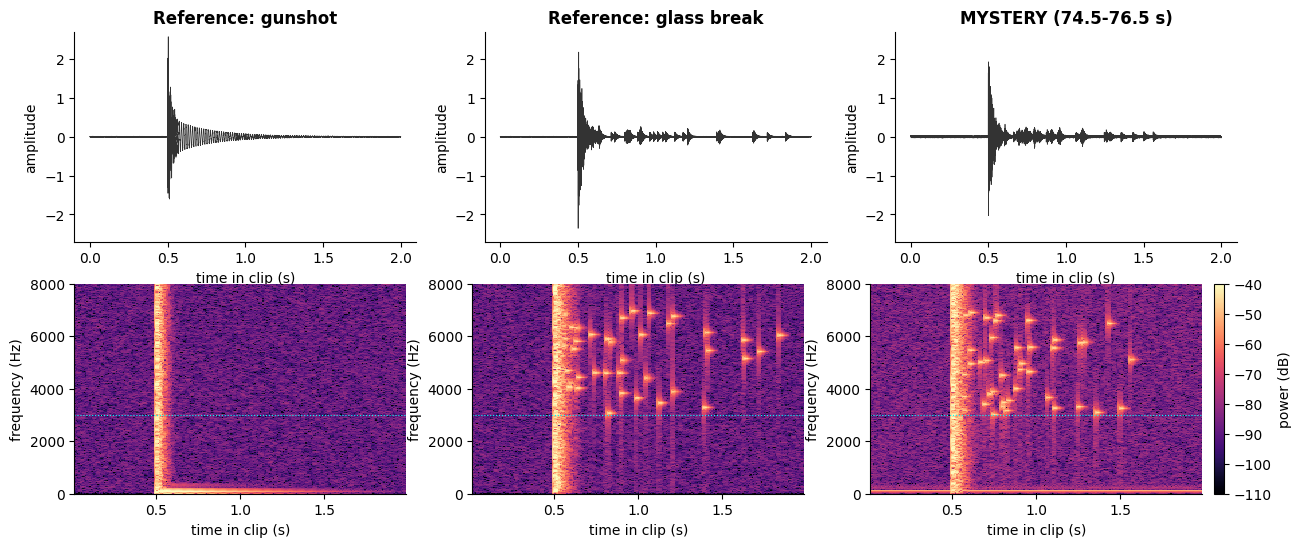

{'Reference: gunshot': 0.003, 'Reference: glass break': 0.989, 'MYSTERY (74.5-76.5 s)': 0.873}
VERDICT: BREAKING GLASS -- 87.3% of the post-impact energy is above 3 kHz (glass ref 98.9%, gunshot ref 0.3%).
  Reference: gunshot       impact peak |x| = 2.57, impact RMS = 0.411
  Reference: glass break   impact peak |x| = 2.36, impact RMS = 0.363
  MYSTERY (74.5-76.5 s)    impact peak |x| = 2.03, impact RMS = 0.337


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
lim = 1.05 * max(np.abs(x).max() for x in clips.values())   # one shared amplitude scale
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
for col, (name, x) in enumerate(clips.items()):
    tt = np.arange(x.size) / FS
    axes[0, col].plot(tt, x, color="#333333", lw=0.5)
    axes[0, col].set_title(name, fontweight="bold")
    axes[0, col].set_xlabel("time in clip (s)"); axes[0, col].set_ylabel("amplitude")
    axes[0, col].set_ylim(-lim, lim)
    f, ts, S = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    im = axes[1, col].pcolormesh(ts, f, 10 * np.log10(S + 1e-12), shading="auto",
                                 cmap="magma", vmin=-110, vmax=-40)
    axes[1, col].set_ylim(0, 8000)
    axes[1, col].set_xlabel("time in clip (s)"); axes[1, col].set_ylabel("frequency (Hz)")
    axes[1, col].axhline(3000, color="cyan", lw=0.8, ls=":")
fig.colorbar(im, ax=axes[1, :], label="power (dB)", fraction=0.02, pad=0.01)
plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
hf_fraction = {}
for name, x in clips.items():
    f, ts, S = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    window = (ts >= 0.5 + 0.2) & (ts <= 0.5 + 1.2)
    E = S[:, window]
    hf_fraction[name] = float(E[f > 3000].sum() / E.sum())

print({k: round(v, 3) for k, v in hf_fraction.items()})

# TODO 4: verdict -- nearest reference on the decisive feature
d_gun = abs(hf_fraction["MYSTERY (74.5-76.5 s)"] - hf_fraction["Reference: gunshot"])
d_glass = abs(hf_fraction["MYSTERY (74.5-76.5 s)"] - hf_fraction["Reference: glass break"])
verdict = "BREAKING GLASS" if d_glass < d_gun else "GUNSHOT"
print(f"VERDICT: {verdict} -- {hf_fraction['MYSTERY (74.5-76.5 s)']:.1%} of the post-impact energy is above 3 kHz "
      f"(glass ref {hf_fraction['Reference: glass break']:.1%}, gunshot ref {hf_fraction['Reference: gunshot']:.1%}).")

# the waveforms alone: the impact itself looks the same in all three
for name, x in clips.items():
    imp = x[int(0.5 * FS): int(0.6 * FS)]
    print(f"  {name:<24} impact peak |x| = {np.abs(imp).max():.2f}, impact RMS = {np.sqrt((imp**2).mean()):.3f}")


**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_

**From the waveforms alone: no, not confidently.** All three show the same thing at 0.5 s — a sharp spike that decays —
with impact peaks of 2.57 (gunshot), 2.36 (glass) and 2.03 (mystery). The glass and mystery tails have small extra
bursts, but on a waveform they could just as easily be echoes or a noisy recording. The waveform answers *when* and
*how loud*, which is the same for both candidate sounds.

**What the spectrogram adds** is the third dimension the waveform collapses: **time × frequency × magnitude** (Slide 57)
— time on x, frequency on y, power as colour. Now the two references look completely different:

- **Gunshot:** a **vertical stripe** (broadband impact) plus a **horizontal band** near the bottom (the ~70 Hz boom),
  then nothing above 3 kHz — only **0.3%** of its post-impact energy is above 3 kHz.
- **Glass:** the same vertical stripe, followed by **scattered high-frequency specks** between ~3 and 7 kHz for about a
  second — the individual shards ringing — **98.9%** above 3 kHz.
- **Mystery:** the vertical stripe followed by the **same scattered specks** — **87.3%** above 3 kHz.

**The scattered high-frequency specks decided the verdict: breaking glass.** One trap worth noting: the mystery
spectrogram also has a thin **horizontal band near the bottom**, which could be misread as the gunshot's boom. It isn't —
it is the 120 Hz background hum present in the whole 70–80 s recording, before and after the event (visible in the
Task 5 spectrogram). Checking whether a feature is *part of the event* or *part of the background* is exactly why the
comparison needs the full time axis, not just the 2-second clip.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

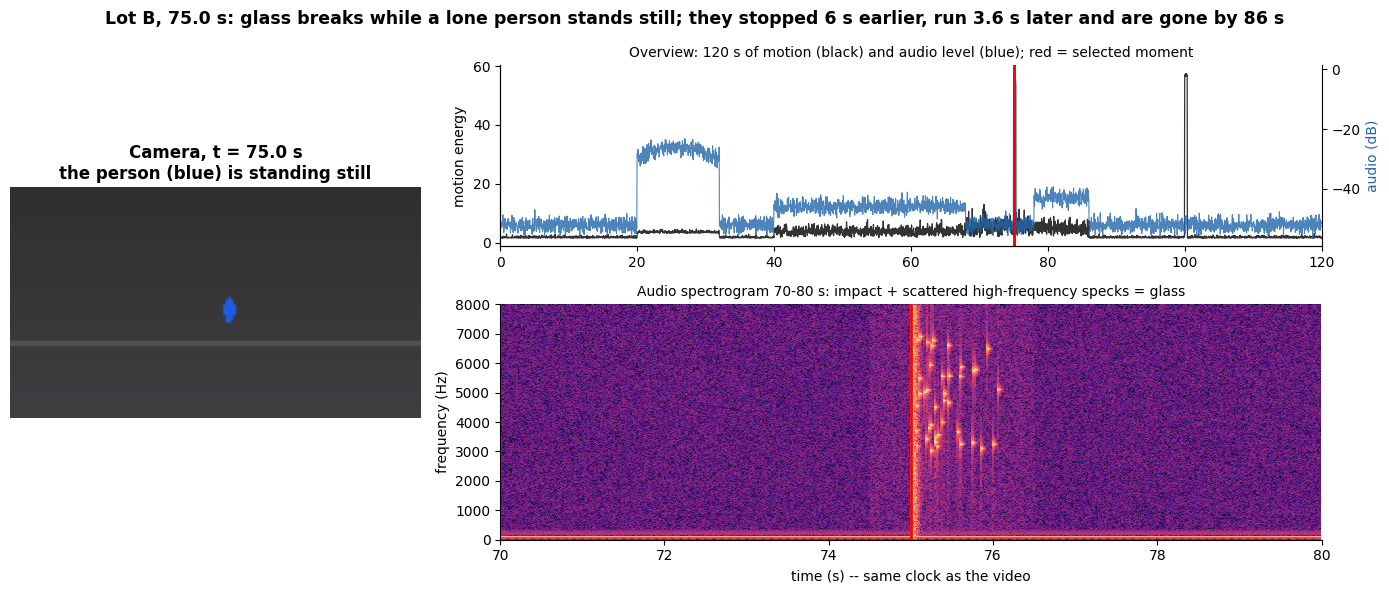

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
i_sel = int(np.argmin(np.abs(cctv.time_s - t_sel)))

# 1. the video frame at the selected moment (detail)
ax_img = fig.add_subplot(gs[:, 0])
ax_img.imshow(render_frame(cctv.iloc[i_sel]))
ax_img.set_title(f"Camera, t = {cctv.time_s[i_sel]:.1f} s\nthe person (blue) is standing still", fontweight="bold")
ax_img.axis("off")

# 2. the full 120 s overview: motion + audio on a shared time axis
ax_tl = fig.add_subplot(gs[0, 1])
ax_tl.plot(cctv.time_s, cctv.motion_energy, color="#333333", lw=0.9, label="motion energy")
ax_tl.set_ylabel("motion energy"); ax_tl.set_xlim(0, 120)
ax_a = ax_tl.twinx()
ax_a.plot(cctv.time_s, cctv.audio_level_db, color="#2166ac", lw=0.8, alpha=0.8, label="audio level")
ax_a.set_ylabel("audio (dB)", color="#2166ac")
ax_a.spines["right"].set_visible(True)
for a in (ax_tl, ax_a):
    a.axvline(t_sel, color="red", lw=2)
ax_tl.set_title("Overview: 120 s of motion (black) and audio level (blue); red = selected moment", fontsize=10)

# 3. the spectrogram detail, same time reference
ax_sp = fig.add_subplot(gs[1, 1])
f, ts, S = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
ax_sp.pcolormesh(ts + t_audio[0], f, 10 * np.log10(S + 1e-12), shading="auto", cmap="magma", vmin=-110, vmax=-40)
ax_sp.axvline(t_sel, color="red", lw=2)
ax_sp.set_ylim(0, 8000); ax_sp.set_xlim(70, 80)
ax_sp.set_xlabel("time (s) -- same clock as the video"); ax_sp.set_ylabel("frequency (Hz)")
ax_sp.set_title("Audio spectrogram 70-80 s: impact + scattered high-frequency specks = glass", fontsize=10)

# 4. conclusion-style title
fig.suptitle("Lot B, 75.0 s: glass breaks while a lone person stands still; "
             "they stopped 6 s earlier, run 3.6 s later and are gone by 86 s", fontsize=12.5, fontweight="bold")
plt.tight_layout(); plt.show()


**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_

With audio shifted **+2 s**, the bang would be drawn at **77.0 s** instead of 75.0 s. The person is still standing then
(standing ends at 78.1 s), so the briefing would still *look* plausible — which is the danger. The derived timeline
would be wrong in ways that change the story: "stood still for **8.3 s**, glass broke, ran **1.6 s** later" instead of
6.3 s and 3.6 s. A reviewer could reasonably conclude the person broke the glass and fled almost instantly, or — with
a slightly bigger offset — that they started running *before* the glass broke, which flips cause and effect. A 2-second
error at 30 fps is a 60-frame misalignment, far larger than anything the eye would accept as "the same moment".

**The overview panel (top right) exposes it**, because it puts both modalities on one time axis and the clip contains
events that *must* coincide in both:

- the **car pass (20–32 s)** raises motion energy and audio level (engine, ~−29 dB) at the same instants — with a
  +2 s offset the audio plateau would start and end 2 s after the motion plateau;
- the **switch from standing to running (78.6 s)** raises both footstep noise and motion energy together.

Those paired edges act as built-in sync markers. The single-moment panels (the frame and the spectrogram) cannot reveal
the error, because each is internally consistent; only the panel that overlays two modalities against a shared clock
can show that they disagree. That is Slide 61's point: **synchronization is a precondition of multimodal
interpretation**, and it needs a check, not an assumption.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_

**Briefing note — Lot B incident, last night**

**What happened.** A single person walked into Lot B at **40.0 s**, stopped at **68.7 s** and stood still; at
**75.0 s** glass broke — the spectrogram puts **87.3%** of the post-impact energy above 3 kHz, matching the vendor's
glass-break reference (98.9%) and not the gunshot reference (0.3%) — and **3.6 s later (78.6 s)** they ran (peak
45.5 px/s) and were out of frame by **86 s**; the lights came on at **100 s** (brightness 62 → 148). A car passed
through at 20–32 s, before the person arrived, and shows no link to the event in this log. **Treat it as a
break-in / vandalism response, not an armed-incident response.**

**What to look at first: the synchronized one-screen view.** It follows the lecture's structure → pattern → change →
event → meaning chain on one page — the timeline gives the overview, and at the selected moment the video frame and the
spectrogram back the claim with **two modalities at the same timestamp**. The keyframes alone would show a person but
not what the sound was; the spectrogram alone would show glass but not who was there.

**Storage policy.** Keep continuous low-resolution recording (360p, 10 fps ≈ **217 TB/day** uncompressed for 400
cameras, vs **5,866 TB/day** at 1080p30) and save **full-resolution, full-frame-rate clips around detected events** —
audio level above −20 dB, brightness jumps, motion — using exactly the event detectors from Task 3. The one thing the
policy must **not** sacrifice is the **audio at its full 16 kHz sample rate**: the glass signature lives at 3–7 kHz,
and an 8 kHz recording could only represent frequencies up to 4 kHz (Nyquist), which would erase most of the evidence
that decided today's verdict. It is also cheap — about **1 TB/day** for all 400 cameras at 16-bit, under 0.5% of even
the low-resolution video.